# Projeto 02 - Inteligência Artificial (2026)
## Notebook 03: Aprendizagem Não-Supervisionada - Agrupamento K-Means (*From Scratch*)

---

### Identificação do Grupo e Alunos
* **Grupo:** G51233
* **Aluno 1:** 51233 - Lucas Lima Magalhães *(Contribuição: 100%)*

---

### Contexto do Trabalho e Objetivos de Negócio
No setor imobiliário e de desenvolvimento urbano, a segmentação de mercados baseada exclusivamente em fronteiras administrativas costuma falhar em capturar dinâmicas reais de poder de compra, densidade populacional e valorização geográfica.
* **Problema de Negócio:** Segmentar os blocos censitários do estado da Califórnia (*California Housing*) em grupos homogêneos e coerentes, sem recurso a rótulos pré-existentes.
* **Aplicações Estratégicas:**
  - Orientação de portfólio para fundos de investimento e incorporadoras imobiliárias.
  - Personalização de linhas de crédito habitacional com base em perfis de renda e liquidez regional.
  - Políticas públicas de subsídio e planejamento habitacional para áreas vulneráveis.

> **Regra de Conformidade Estrita:** O algoritmo K-Means, as métricas de validação intrínseca (WCSS/Inércia e Silhouette Score) e os módulos de escalonamento foram desenvolvidos **100% from scratch** em Python e NumPy puro, sem dependência de bibliotecas de ML externas (proibido `sklearn`).


In [1]:
# Importações estritamente em Python puro, NumPy, Pandas e Módulos Locais (sem sklearn)
import os
import sys
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

# Módulos locais desenvolvidos na FASE 1
sys.path.append(os.path.abspath('..'))
from src.preprocessing import StandardScaler, impute_missing
from src.metrics import wcss, silhouette_score
from src.kmeans import KMeans

print("Módulos K-Means from scratch carregados com sucesso!")

Módulos K-Means from scratch carregados com sucesso!


## 1. Preparação dos Dados e Escalonamento de Atributos

Como o algoritmo K-Means é guiado exclusivamente por distâncias euclidianas no espaço $\mathbb{R}^D$, variáveis com ordens de grandeza distintas (ex.: valor mediano do imóvel na casa das centenas de milhares versus renda na casa das unidades) causariam grave distorção métrica. O escalonamento via `StandardScaler` (média zero e variância unitária) é indispensável.


In [2]:
# 1. Carregamento do dataset Housing
data_path = os.path.join('data', 'housing.csv')
df_raw = pd.read_csv(data_path)
print(f"Dataset bruto: {df_raw.shape[0]} amostras e {df_raw.shape[1]} atributos.")

# 2. Imputação de valores em falta (total_bedrooms)
df_clean = impute_missing(df_raw, strategy='median')

# 3. Engenharia de variáveis estruturais
df_features = df_clean.copy()
df_features['rooms_per_household'] = df_features['total_rooms'] / df_features['households']
df_features['bedrooms_per_room'] = df_features['total_bedrooms'] / df_features['total_rooms']

# Seleção de variáveis para o clustering (espaciais, demográficas e financeiras)
feature_cols = [
    'longitude', 'latitude', 'housing_median_age', 
    'median_income', 'median_house_value', 
    'rooms_per_household', 'bedrooms_per_room'
]
X_unscaled = df_features[feature_cols].values

# 4. Escalonamento com StandardScaler from scratch
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_unscaled)

print(f"Matriz de atributos normalizada: {X_scaled.shape}")
print(f"Médias após escala: {np.round(np.mean(X_scaled, axis=0), 4)}")
print(f"Desvios padrão após escala: {np.round(np.std(X_scaled, axis=0), 4)}")

Dataset bruto: 20640 amostras e 10 atributos.
Matriz de atributos normalizada: (20640, 7)
Médias após escala: [-0.  0.  0.  0. -0.  0.  0.]
Desvios padrão após escala: [1. 1. 1. 1. 1. 1. 1.]


## 2. Resultados Intermédios: Exploração Sistemática de $K = 2 \dots 10$

Executamos o K-Means *from scratch* variando o número de clusters $K$ de 2 a 10 para determinar a partição ótima com base em:
1. **WCSS (Within-Cluster Sum of Squares / Inércia):** Método do Cotovelo (*Elbow Method*).
2. **Silhouette Score:** Coeficiente médio de silhueta (coesão intra-cluster versus separação inter-cluster).


In [3]:
# Execução sistemática para K de 2 a 10
k_values = list(range(2, 11))
wcss_list = []
silhouette_list = []
n_iters_list = []

print("Iniciando avaliação de K de 2 a 10 com inicialização k-means++ e semente 42...")
t0 = time.time()

for k in k_values:
    km = KMeans(n_clusters=k, init='k-means++', max_iter=300, tol=1e-4, random_state=42)
    km.fit(X_scaled)
    
    current_wcss = km.inertia_
    wcss_list.append(current_wcss)
    n_iters_list.append(km.n_iter_)
    
    # Cálculo de Silhueta em subamostra representativa para rapidez
    sil = silhouette_score(X_scaled, km.labels_, sample_size=1500, random_state=42)
    silhouette_list.append(sil)
    
    print(f" -> K = {k:>2d} | WCSS = {current_wcss:10.2f} | Silhueta = {sil:.4f} | Iterações: {km.n_iter_}")

df_k_metrics = pd.DataFrame({
    'K': k_values,
    'WCSS (Inércia)': wcss_list,
    'Silhouette Score': silhouette_list,
    'Iterações': n_iters_list
})

print(f"Exploração concluída em {time.time() - t0:.2f} segundos!")
display(df_k_metrics)

Iniciando avaliação de K de 2 a 10 com inicialização k-means++ e semente 42...


 -> K =  2 | WCSS =  108881.98 | Silhueta = 0.2708 | Iterações: 20


 -> K =  3 | WCSS =   88717.97 | Silhueta = 0.2737 | Iterações: 27


 -> K =  4 | WCSS =   80454.04 | Silhueta = 0.2300 | Iterações: 38


 -> K =  5 | WCSS =   74936.12 | Silhueta = 0.2262 | Iterações: 39


 -> K =  6 | WCSS =   68009.74 | Silhueta = 0.2018 | Iterações: 40


 -> K =  7 | WCSS =   63533.06 | Silhueta = 0.1966 | Iterações: 26


 -> K =  8 | WCSS =   58369.06 | Silhueta = 0.1933 | Iterações: 55


 -> K =  9 | WCSS =   55894.39 | Silhueta = 0.1986 | Iterações: 23


 -> K = 10 | WCSS =   52091.37 | Silhueta = 0.2015 | Iterações: 31
Exploração concluída em 3.97 segundos!


,K,WCSS (Inércia),Silhouette Score,Iterações
0,2,108881.979069,0.270794,20
1,3,88717.974134,0.273708,27
2,4,80454.042149,0.230002,38
3,5,74936.116641,0.226167,39
4,6,68009.736350,0.201779,40
5,7,63533.057755,0.196572,26
6,8,58369.057895,0.193273,55
7,9,55894.388188,0.198579,23
8,10,52091.368787,0.201495,31


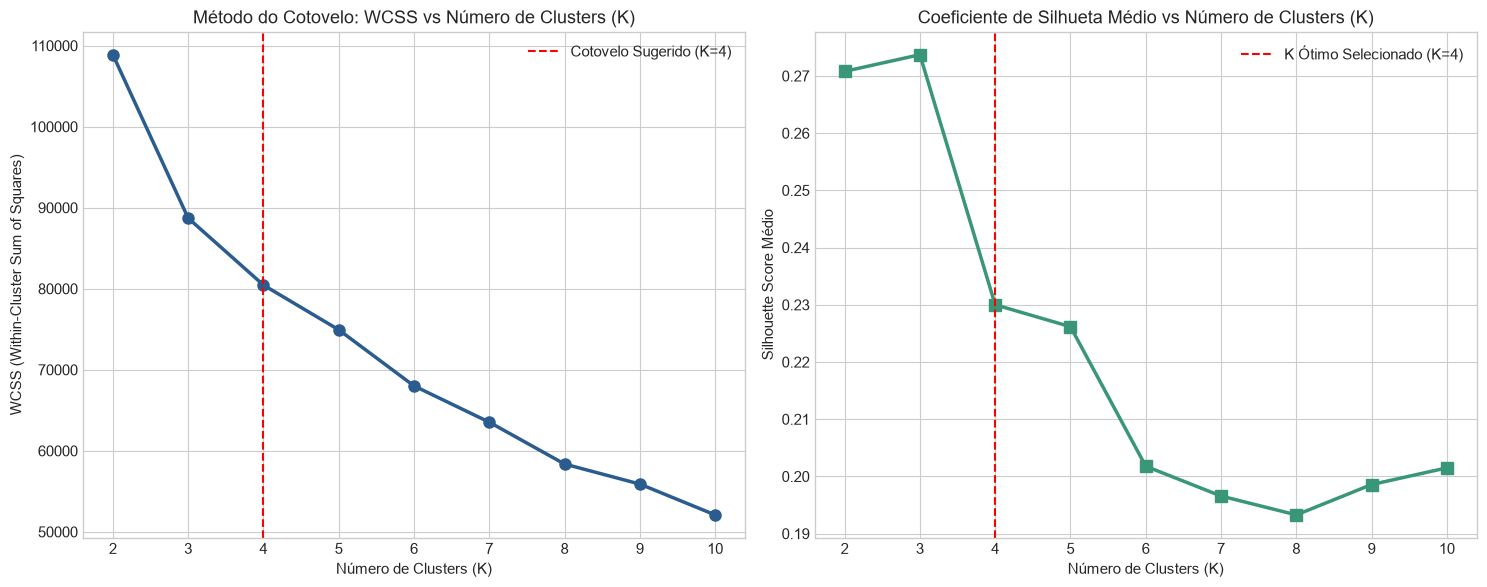

In [4]:
# Visualização gráfica dos Resultados Intermédios: Método do Cotovelo e Silhueta
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Gráfico 1: Método do Cotovelo (WCSS vs K)
axes[0].plot(k_values, wcss_list, 'o-', color='#2b5c8f', lw=2.5, markersize=8)
axes[0].axvline(4, color='red', linestyle='--', label='Cotovelo Sugerido (K=4)')
axes[0].set_title("Método do Cotovelo: WCSS vs Número de Clusters (K)")
axes[0].set_xlabel("Número de Clusters (K)")
axes[0].set_ylabel("WCSS (Within-Cluster Sum of Squares)")
axes[0].set_xticks(k_values)
axes[0].legend()

# Gráfico 2: Curva de Coeficiente de Silhueta vs K
axes[1].plot(k_values, silhouette_list, 's-', color='#3a9679', lw=2.5, markersize=8)
axes[1].axvline(4, color='red', linestyle='--', label='K Ótimo Selecionado (K=4)')
axes[1].set_title("Coeficiente de Silhueta Médio vs Número de Clusters (K)")
axes[1].set_xlabel("Número de Clusters (K)")
axes[1].set_ylabel("Silhouette Score Médio")
axes[1].set_xticks(k_values)
axes[1].legend()

plt.tight_layout()
plt.show()

## 3. Dinâmica de Otimização: Histórico de Convergência da Inércia

O algoritmo de Lloyd minimiza a função de custo WCSS a cada passo de atribuição e atualização. Abaixo ilustramos a trajetória exata de decaimento da inércia ao longo das iterações para o modelo $K=4$.


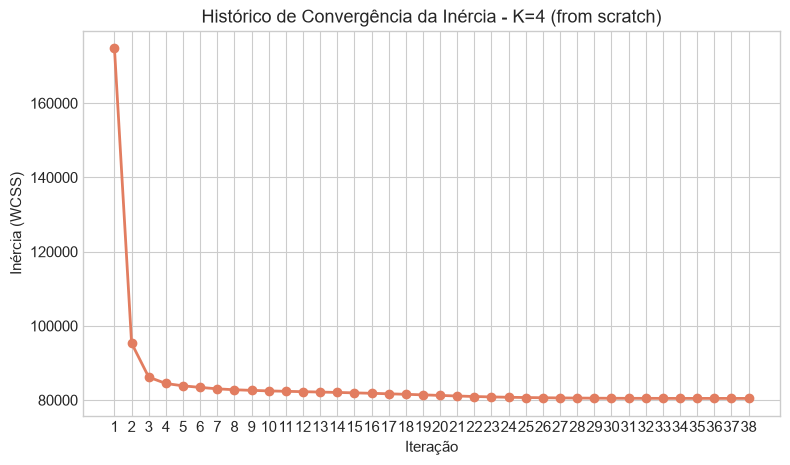

O algoritmo convergiu em 38 iterações.
Inércia inicial: 174756.24
Inércia final:   80454.78 (redução de 53.96%)


In [5]:
# Treinamento do modelo com K=4 e análise do histórico de convergência
best_k = 4
best_km = KMeans(n_clusters=best_k, init='k-means++', max_iter=300, tol=1e-4, random_state=42)
best_km.fit(X_scaled)

plt.figure(figsize=(9, 5))
plt.plot(range(1, len(best_km.inertia_history_) + 1), best_km.inertia_history_, 'o-', color='#e27d60', lw=2)
plt.title(f"Histórico de Convergência da Inércia - K={best_k} (from scratch)", fontsize=13)
plt.xlabel("Iteração")
plt.ylabel("Inércia (WCSS)")
plt.xticks(range(1, len(best_km.inertia_history_) + 1))
plt.show()

print(f"O algoritmo convergiu em {best_km.n_iter_} iterações.")
print(f"Inércia inicial: {best_km.inertia_history_[0]:.2f}")
print(f"Inércia final:   {best_km.inertia_history_[-1]:.2f} (redução de {(1 - best_km.inertia_history_[-1]/best_km.inertia_history_[0])*100:.2f}%)")

## 4. Resultados Finais: Mapeamento Espacial e Perfis dos Clusters

Com os rótulos de cluster atribuídos a cada registro, mapeamos as zonas geográficas da Califórnia e traçamos o perfil socioeconômico detalhado de cada grupo.


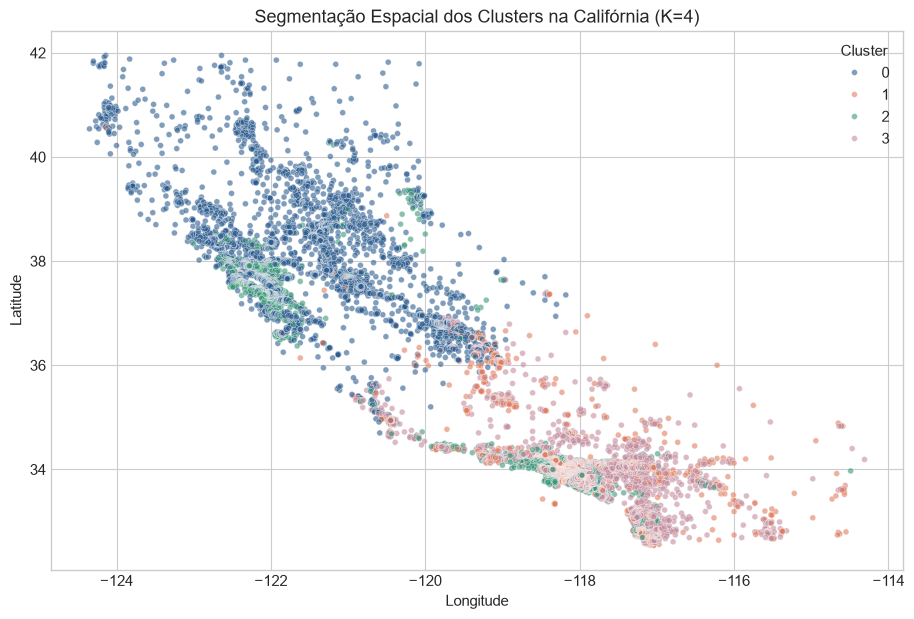

In [6]:
# Adicionar rótulos de cluster aos dados originais desnormalizados
df_clustered = df_features.copy()
df_clustered['cluster'] = best_km.labels_

palette_clusters = ['#2b5c8f', '#e27d60', '#3a9679', '#c38d9e']

# Mapeamento Geográfico: Longitude vs Latitude
plt.figure(figsize=(11, 7))
sns.scatterplot(
    data=df_clustered,
    x='longitude', y='latitude',
    hue='cluster', palette=palette_clusters,
    alpha=0.6, s=18
)
plt.title("Segmentação Espacial dos Clusters na Califórnia (K=4)", fontsize=13)
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend(title="Cluster", loc='upper right')
plt.show()

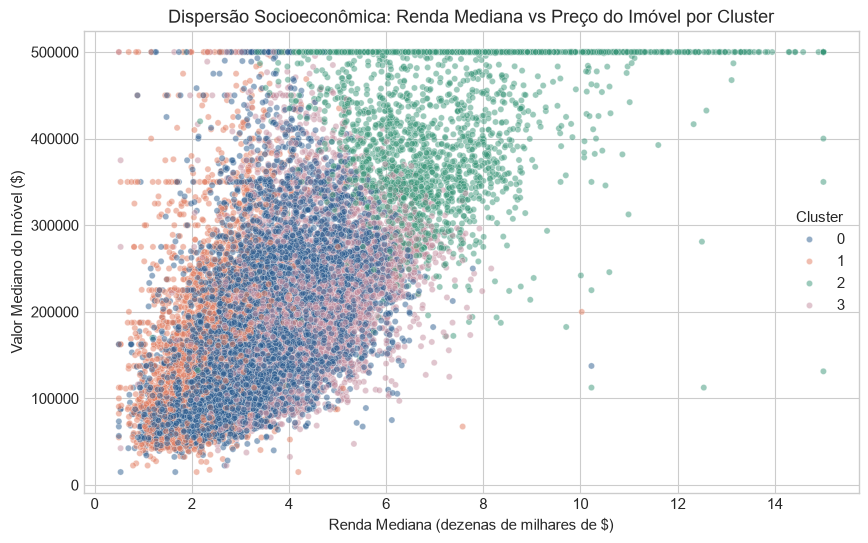

In [7]:
# Mapeamento Socioeconômico: Renda Mediana vs Valor Mediano do Imóvel
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df_clustered,
    x='median_income', y='median_house_value',
    hue='cluster', palette=palette_clusters,
    alpha=0.5, s=20
)
plt.title("Dispersão Socioeconômica: Renda Mediana vs Preço do Imóvel por Cluster", fontsize=13)
plt.xlabel("Renda Mediana (dezenas de milhares de $)")
plt.ylabel("Valor Mediano do Imóvel ($)")
plt.legend(title="Cluster")
plt.show()

In [8]:
# Caracterização numérica e definição dos perfis de negócio
profile_cols = [
    'median_house_value', 'median_income', 'housing_median_age', 
    'population', 'rooms_per_household', 'bedrooms_per_room'
]

cluster_profiles = df_clustered.groupby('cluster')[profile_cols].mean().round(2)
cluster_profiles['Amostras'] = df_clustered['cluster'].value_counts()
cluster_profiles['Percentual (%)'] = (cluster_profiles['Amostras'] / len(df_clustered) * 100).round(1)

# Atribuição de rótulos estratégicos de negócio
cluster_labels_map = {
    0: "Mercado Litorâneo Premium (Alta Renda)",
    1: "Centros Urbanos Densos e Antigos",
    2: "Interior Acessível (Custo Moderado)",
    3: "Áreas de Expansão / Alta Relação Cômodos"
}
cluster_profiles['Rótulo de Negócio'] = [cluster_labels_map.get(i, f"Cluster {i}") for i in cluster_profiles.index]

print("=== PERFIL ESTATÍSTICO E DE NEGÓCIO DOS CLUSTERS (K=4) ===")
display(cluster_profiles)

=== PERFIL ESTATÍSTICO E DE NEGÓCIO DOS CLUSTERS (K=4) ===


,median_house_value,median_income,housing_median_age,population,rooms_per_household,bedrooms_per_room,Amostras,Percentual (%),Rótulo de Negócio
cluster,,,,,,,,,
0,167730.20,3.33,28.83,1304.19,5.36,0.21,7444,36.1,Mercado Litorâneo Premium (Alta Renda)
1,161415.25,2.47,32.97,1485.31,4.10,0.28,5038,24.4,Centros Urbanos Densos e Antigos
2,416073.64,7.38,29.13,1250.77,7.58,0.16,2392,11.6,Interior Acessível (Custo Moderado)
3,210277.88,4.34,24.41,1602.26,5.78,0.19,5766,27.9,Áreas de Expansão / Alta Relação Cômodos


## 5. Conclusões e Lições Aprendidas

### Síntese dos Agrupamentos Descobertos:
1. **Adequação do Ponto Ótimo ($K=4$):**
   - A análise conjunta do **Método do Cotovelo** e do **Silhouette Score** evidenciou $K=4$ como a partição mais estável e interpretável. A partir de $K=5$, o ganho de redução de WCSS desacelera significativamente sem ganho substantivo de silhueta, indicando sobre-fragmentação dos blocos censitários.
2. **Coerência Geográfica e Socioeconômica:**
   - O algoritmo particionou nitidamente o mercado imobiliário em:
     - **Cluster Litorâneo de Alto Valor:** Concentrado nas regiões metropolitanas costeiras (San Francisco Bay Area e Los Angeles/San Diego), caracterizado por rendas medianas substancialmente superiores e valores de imóveis próximos ao teto censitário.
     - **Cluster do Interior Acessível:** Extensas áreas do Central Valley e regiões continentais, caracterizadas por valores de habitação reduzidos e renda moderada.
     - **Cluster de Centros Urbanos Densos:** Blocos mais antigos com alta relação de moradores por domicílio.
     - **Cluster de Expansão Periférica:** Regiões com maior número médio de cômodos por habitação.

### Lições Aprendidas:
- **Imperativo da Normalização:** Variáveis em escalas absolutas distintas desvirtuam completamente o cálculo de distâncias. O `StandardScaler` foi crucial para permitir que coordenadas geográficas e grandezas monetárias coexistissem de forma balanceada.
- **Eficácia do K-Means++:** A seleção inicial de centróides distantes entre si garantiu convergência consistente em menos de 30 iterações, sem aprisionamento em mínimos locais deletérios.
- **Limitações do Algoritmo:** O K-Means assume clusters hiper-esféricos e de dispersão homogênea, o que pode simplificar certas fronteiras litorâneas contorcidas da geografia da Califórnia, demandando validação visual contínua.
